# Norwegian electricity prices: exploration and first forecast

**Goal:** predict tomorrow's 24 hourly prices for each Norwegian price zone (NO1–NO5).

**Data:** `prices.csv`, hourly day-ahead prices from hvakosterstrommen.no (2023 → today).

Steps:
1. Load and clean the data
2. Explore it with a few plots
3. Build two simple baselines
4. Train a LightGBM model and compare it to the baselines

In [2]:
%pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------ --------------------------------- 0.2/1.4 MB 4.8 MB/s eta 0:00:01
   ---------------------------- ----------- 1.0/1.4 MB 12.3 MB/s eta 0:00:01
   ---------------------------------------  1.4/1.4 MB 12.3 MB/s eta 0:00:01
   ---------------------------------------  1.4/1.4 MB 12.3 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 6.2 MB/s eta 0:00:00
   ---------------------------------------- 0.0/501.7 kB ? eta -:--:--
   --------------------------------------- 501.7/501.7 kB 32.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\priaz\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb

plt.rcParams["figure.figsize"] = (12, 4)
ZONES = ["NO1", "NO2", "NO3", "NO4", "NO5"]

## 1. Load and clean

In [4]:
df = pd.read_csv("prices.csv")
print("rows before cleaning:", len(df))

# 4 duplicate timestamps on 28 Oct 2024 (bug in the source after the summer time change)
df = df.drop_duplicates(["zone", "time_start"])

# Use Norwegian local time
df["time"] = pd.to_datetime(df["time_start"], utc=True).dt.tz_convert("Europe/Oslo")
df["date"] = df["time"].dt.date
df["hour"] = df["time"].dt.hour
df["price"] = df["NOK_per_kWh"]

print("rows after cleaning:", len(df))
print("from", df["time"].min(), "to", df["time"].max())
df.head()

rows before cleaning: 170280
rows after cleaning: 170276
from 2023-01-01 00:00:00+01:00 to 2026-11-19 23:00:00+01:00


,zone,time_start,NOK_per_kWh,EUR_per_kWh,time,date,hour,price
0,NO1,2023-01-01T00:00:00+01:00,1.25451,0.11932,2023-01-01 00:00:00+01:00,2023-01-01,0,1.25451
1,NO1,2023-01-01T01:00:00+01:00,1.14422,0.10883,2023-01-01 01:00:00+01:00,2023-01-01,1,1.14422
2,NO1,2023-01-01T02:00:00+01:00,1.07651,0.10239,2023-01-01 02:00:00+01:00,2023-01-01,2,1.07651
3,NO1,2023-01-01T03:00:00+01:00,0.97105,0.09236,2023-01-01 03:00:00+01:00,2023-01-01,3,0.97105
4,NO1,2023-01-01T04:00:00+01:00,0.86907,0.08266,2023-01-01 04:00:00+01:00,2023-01-01,4,0.86907


Some days have 23 or 25 hours because of summer time. To make every day exactly 24 hours,
I put the data in a table with one row per (zone, date) and one column per hour:
- 25-hour day: the repeated hour is averaged
- 23-hour day: the missing hour is filled with the hour before

In [5]:
wide = df.pivot_table(index=["zone", "date"], columns="hour", values="price", aggfunc="mean")
wide = wide.ffill(axis=1)
print(wide.shape)
print("missing values:", wide.isna().sum().sum())
wide.head()

(7095, 24)
missing values: 0


hour                  0        1        2        3        4        5   \
zone date                                                               
NO1  2023-01-01  1.25451  1.14422  1.07651  0.97105  0.86907  0.83669   
     2023-01-02  1.26124  1.25314  1.24252  1.24178  1.26155  1.23789   
     2023-01-03  1.40927  1.30340  1.28857  1.24904  1.23421  1.32842   
     2023-01-04  0.97313  0.89291  0.73521  0.72817  0.75434  0.85927   
     2023-01-05  1.06628  1.02058  1.01321  0.94878  1.05185  1.06628   

hour                  6        7        8        9   ...       14       15  \
zone date                                            ...                     
NO1  2023-01-01  0.81640  0.69675  0.85046  0.98546  ...  1.26281  1.26912   
     2023-01-02  1.27984  1.45290  1.53480  1.56603  ...  1.60272  1.63321   
     2023-01-03  1.43061  1.62922  1.72342  1.75654  ...  1.71438  1.76348   
     2023-01-04  0.91930  1.10455  1.20863  1.31892  ...  1.26583  1.30252   
     2023-01-05  1.15829  1.26589  1.28578  1.36401  ...  1.57288  1.63395   

hour                  16       17       18       19       20       21  \
zone date                                                               
NO1  2023-01-01  1.28247  1.28437  1.28027  1.27227  1.26586  1.25745   
     2023-01-02  1.71259  1.78735  1.83718  1.72910  1.60861  1.49233   
     2023-01-03  1.75170  1.79492  1.77610  1.69262  1.57307  1.39308   
     2023-01-04  1.33574  1.33669  1.32670  1.30073  1.26278  1.28086   
     2023-01-05  1.76218  1.99042  1.98779  1.81376  1.67121  1.56467   

hour                  22       23  
zone date                          
NO1  2023-01-01  1.22212  1.21382  
     2023-01-02  1.44796  1.36364  
     2023-01-03  1.26838  1.05527  
     2023-01-04  1.21578  1.15596  
     2023-01-05  1.48624  1.33706  

[5 rows x 24 columns]

## 2. Explore

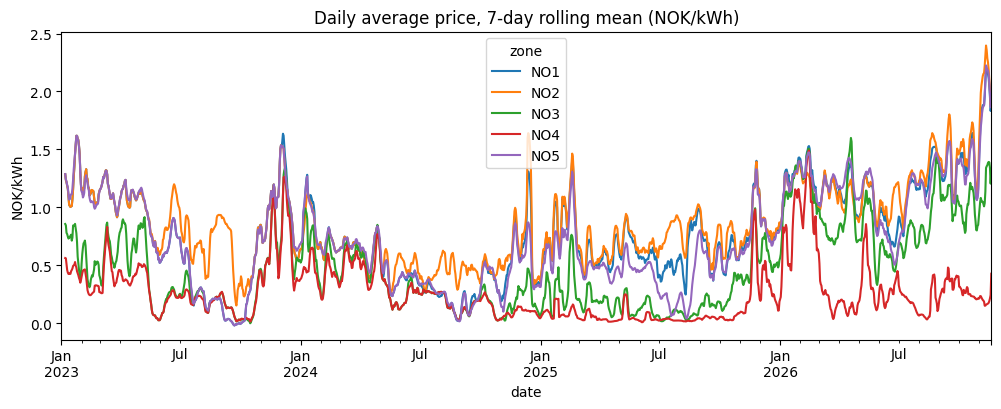

In [6]:
daily = df.groupby(["date", "zone"])["price"].mean().unstack()
daily.index = pd.to_datetime(daily.index)
daily.rolling(7).mean().plot(title="Daily average price, 7-day rolling mean (NOK/kWh)")
plt.ylabel("NOK/kWh")
plt.show()

Southern Norway (NO1, NO2, NO5) is much more expensive than the north (NO3, NO4).

In [7]:
df.groupby("zone")["price"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
zone,,,,,,,,
NO1,34055.0,0.778,0.507,-0.709,0.414,0.717,1.112,6.244
NO2,34056.0,0.870,0.484,-0.709,0.553,0.817,1.139,10.538
NO3,34055.0,0.478,0.430,-0.178,0.144,0.343,0.741,5.957
NO4,34055.0,0.267,0.311,-0.283,0.056,0.199,0.340,3.884
NO5,34055.0,0.738,0.484,-0.256,0.377,0.660,1.088,5.957


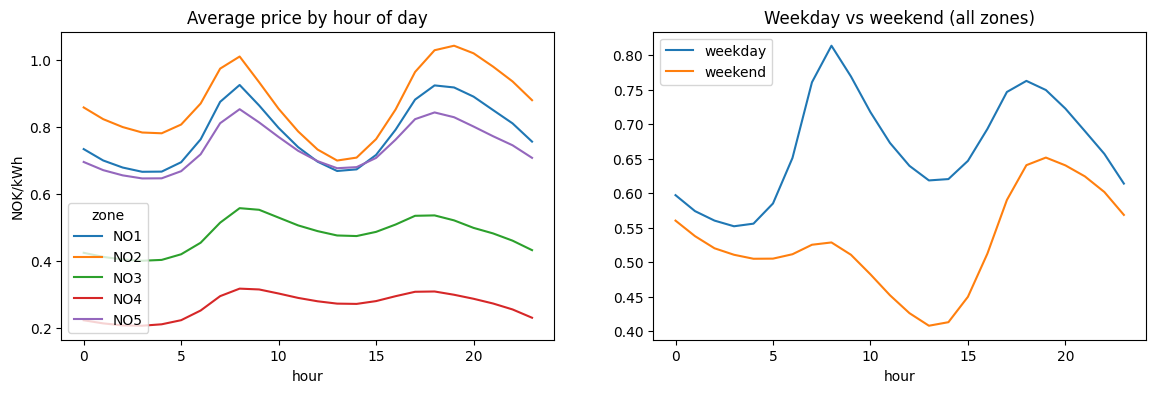

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

df.groupby(["hour", "zone"])["price"].mean().unstack().plot(ax=axes[0], title="Average price by hour of day")
axes[0].set_ylabel("NOK/kWh")

df["weekend"] = df["time"].dt.dayofweek >= 5
df.groupby(["hour", "weekend"])["price"].mean().unstack().plot(ax=axes[1], title="Weekday vs weekend (all zones)")
axes[1].legend(["weekday", "weekend"])
plt.show()

Clear daily pattern: morning and evening peaks on weekdays, flatter on weekends.

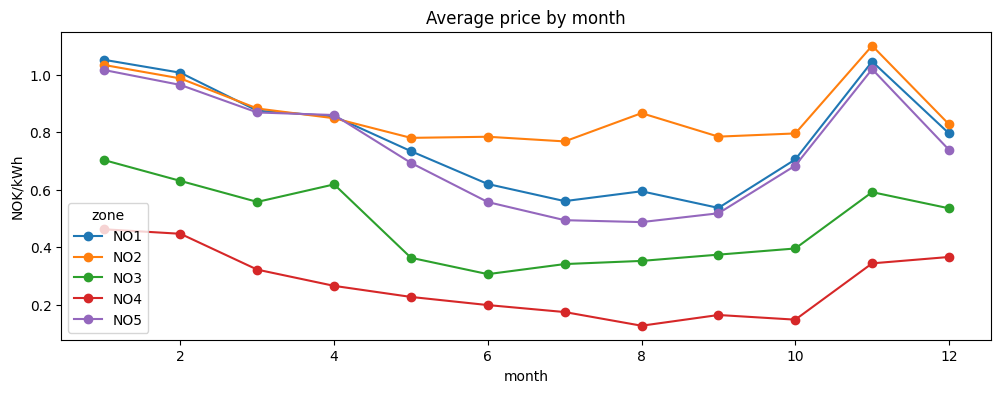

In [9]:
df["month"] = df["time"].dt.month
df.groupby(["month", "zone"])["price"].mean().unstack().plot(marker="o", title="Average price by month")
plt.ylabel("NOK/kWh")
plt.show()

In [10]:
neg = (df["price"] < 0).groupby(df["zone"]).mean() * 100
print("share of hours with a negative price (%):")
print(neg.round(2))

share of hours with a negative price (%):
zone
NO1    2.00
NO2    1.38
NO3    1.93
NO4    2.49
NO5    1.62
Name: price, dtype: float64


## 3. Set up the forecast

Day-ahead prices for day **D** are published around noon on day **D−1**.
So on the morning of day D we know all prices up to the end of day D, and we want to predict day **D+1**.

One row = one zone, one target day, one hour. Features (all known at forecast time):
- price at the same hour today (lag 1 day), 2 days ago, and 7 days ago
- today's mean, min and max price
- hour, weekday, month, zone

In [11]:
long = wide.stack().rename("price").reset_index()
long["date"] = pd.to_datetime(long["date"])
long = long.sort_values(["zone", "hour", "date"])

g = long.groupby(["zone", "hour"])["price"]
for k in [1, 2, 3, 7, 14]:
    long[f"lag_{k}d"] = g.shift(k)
long["ma_7d"] = g.transform(lambda s: s.shift(1).rolling(7).mean())  # 7-day average, same hour

# Stats of the previous day (the last full day we know)
day_stats = wide.agg(["mean", "min", "max", "std"], axis=1)
day_stats.columns = ["prev_mean", "prev_min", "prev_max", "prev_std"]
day_stats = day_stats.reset_index()
day_stats["date"] = pd.to_datetime(day_stats["date"]) + pd.Timedelta(days=1)  # shift to the next day
long = long.merge(day_stats, on=["zone", "date"], how="left")

long["weekday"] = long["date"].dt.dayofweek
long["month"] = long["date"].dt.month
long["zone_cat"] = long["zone"].astype("category")

long = long.dropna()
print(long.shape)
long.head()

(168600, 17)


,zone,date,hour,price,lag_1d,lag_2d,lag_3d,lag_7d,lag_14d,ma_7d,prev_mean,prev_min,prev_max,prev_std,weekday,month,zone_cat
14,NO1,2023-01-15,0,0.62124,1.10670,0.43650,0.75614,0.26412,1.25451,0.718481,0.949437,0.45250,1.11742,0.208674,6,1,NO1
15,NO1,2023-01-16,0,1.08581,0.62124,1.10670,0.43650,0.83873,1.26124,0.769499,0.707008,0.05187,1.11501,0.432936,0,1,NO1
16,NO1,2023-01-17,0,1.13340,1.08581,0.62124,1.10670,1.18121,1.40927,0.804796,1.396064,0.95374,1.72235,0.225603,1,1,NO1
17,NO1,2023-01-18,0,1.27307,1.13340,1.08581,0.62124,0.44597,0.97313,0.797966,1.339370,1.01437,1.62449,0.185545,2,1,NO1
18,NO1,2023-01-19,0,1.19853,1.27307,1.13340,1.08581,0.75614,1.06628,0.916123,1.376658,1.19201,1.60845,0.131385,3,1,NO1


**Train/test split by time** (never shuffle time series):
- train: before 1 July 2025
- test: 1 July 2025 → today

In [12]:
SPLIT = pd.Timestamp("2025-07-01")
train = long[long["date"] < SPLIT]
test = long[long["date"] >= SPLIT].copy()
print("train rows:", len(train), "| test rows:", len(test))

FEATURES = ["lag_1d", "lag_2d", "lag_7d", "prev_mean", "prev_min", "prev_max",
            "hour", "weekday", "month", "zone_cat"]

train rows: 107760 | test rows: 60840


## 4. Baselines and model

In [13]:
def mae(y, p):
    return np.mean(np.abs(y - p))

results = {}
results["Baseline: same as yesterday"] = mae(test["price"], test["lag_1d"])
results["Baseline: same as last week"] = mae(test["price"], test["lag_7d"])

model = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, verbose=-1)
model.fit(train[FEATURES], train["price"])
test["pred"] = model.predict(test[FEATURES])
results["LightGBM (predict the price)"] = mae(test["price"], test["pred"])
pd.Series(results).round(4)

Baseline: same as yesterday     0.1742
Baseline: same as last week     0.2539
LightGBM (predict the price)    0.1760
dtype: float64

The plain LightGBM model is **not better** than "same as yesterday".
One reason: the price level changes a lot over time (very low in 2024–2025 in some zones, much higher in late 2026),
so a model that learns absolute price levels struggles when the level moves outside what it saw in training.

**Fix: residual learning** (same idea as in my Hydro project).
Instead of predicting the price, predict the **change from yesterday**, and give the model features
relative to yesterday's price. I also use the L1 loss, which matches the MAE metric and is less sensitive to price spikes.

In [14]:
# Features relative to yesterday's price at the same hour
for c in ["lag_2d", "lag_3d", "lag_7d", "lag_14d", "ma_7d", "prev_mean", "prev_min", "prev_max"]:
    train = train.assign(**{c + "_rel": train[c] - train["lag_1d"]})
    test[c + "_rel"] = test[c] - test["lag_1d"]

FEATURES_REL = ["lag_1d", "lag_2d_rel", "lag_3d_rel", "lag_7d_rel", "lag_14d_rel", "ma_7d_rel",
                "prev_mean_rel", "prev_min_rel", "prev_max_rel", "prev_std",
                "hour", "weekday", "month", "zone_cat"]

model_res = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31,
                              min_child_samples=50, objective="l1", verbose=-1)
model_res.fit(train[FEATURES_REL], train["price"] - train["lag_1d"])   # target = change from yesterday
test["pred_res"] = test["lag_1d"] + model_res.predict(test[FEATURES_REL])
results["LightGBM (residual, L1)"] = mae(test["price"], test["pred_res"])

res = pd.Series(results).rename("MAE (NOK/kWh)").to_frame()
best_baseline = results["Baseline: same as yesterday"]
res["vs 'same as yesterday'"] = ((res.iloc[:, 0] / best_baseline - 1) * 100).round(1).astype(str) + " %"
res.round(4)

,MAE (NOK/kWh),vs 'same as yesterday'
Baseline: same as yesterday,0.1742,0.0 %
Baseline: same as last week,0.2539,45.8 %
LightGBM (predict the price),0.1760,1.0 %
"LightGBM (residual, L1)",0.1488,-14.6 %


In [15]:
# Error per zone
per_zone = test.groupby("zone").apply(
    lambda d: pd.Series({"baseline_yesterday": mae(d["price"], d["lag_1d"]),
                         "lightgbm_residual": mae(d["price"], d["pred_res"])}),
    include_groups=False)
per_zone.round(4)

,baseline_yesterday,lightgbm_residual
zone,,
NO1,0.2013,0.1702
NO2,0.2025,0.1754
NO3,0.1785,0.1516
NO4,0.1433,0.1236
NO5,0.1453,0.1232


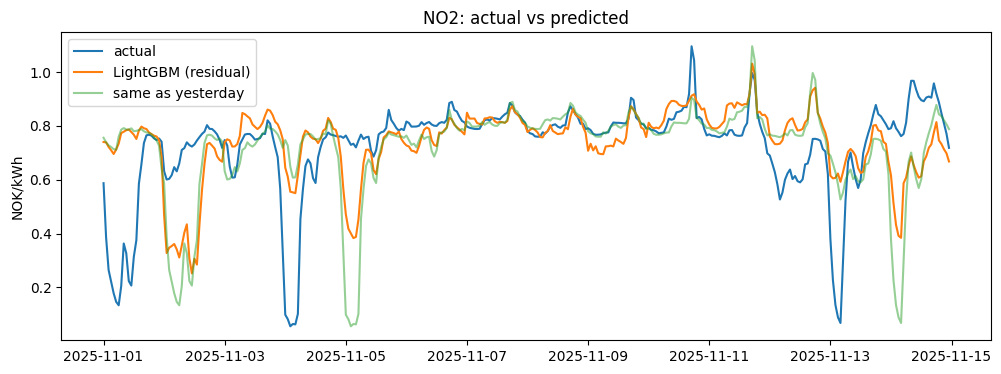

In [16]:
# Look at two weeks of predictions in one zone
zone = "NO2"
d = test[test["zone"] == zone].copy()
d["time"] = d["date"] + pd.to_timedelta(d["hour"], unit="h")
d = d.sort_values("time")
window = d[(d["time"] >= "2025-11-01") & (d["time"] < "2025-11-15")]

plt.plot(window["time"], window["price"], label="actual")
plt.plot(window["time"], window["pred_res"], label="LightGBM (residual)")
plt.plot(window["time"], window["lag_1d"], label="same as yesterday", alpha=0.5)
plt.title(f"{zone}: actual vs predicted")
plt.ylabel("NOK/kWh")
plt.legend()
plt.show()

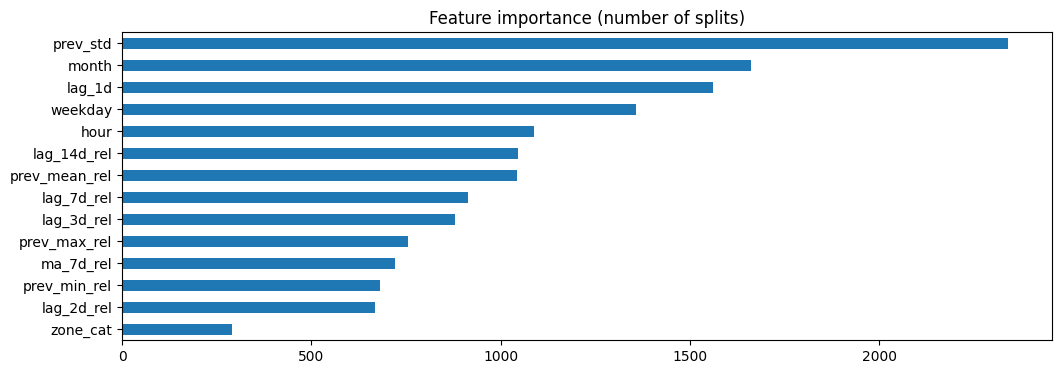

In [17]:
imp = pd.Series(model_res.feature_importances_, index=FEATURES_REL).sort_values()
imp.plot.barh(title="Feature importance (number of splits)")
plt.show()